<div align="center">
    <h1>Airbnb Pricing Analysis: Budapest</h1>
    <h3>STAT 301: Group Final Report</h3>
    <br>
    <b>Group Number:</b> 9<br>
    <b>Date:</b> November 2025<br>
    <br>
    <b>Team Members:</b><br>
    Prateek Paul<br>
    Banu Polat<br>
    Martin Lou<br>
    Marc Shi
</div>

<hr>

## Introduction
### Background
Our data comprises Airbnb listings in Budapest, faceted by weekend and weekday availability. While these two datasets share identical features, they contain distinct observations reflecting the timing of the booking. The data encompasses a wide spectrum of short-term rentals, from shared rooms to high-end apartments. Hosts employ dynamic pricing strategies based on a multitude of factors, rather than a single determinant. Prior work shows that price patterns are closely associated with neighborhood characteristics, amenities, and reputation (Gibbs et al., 2018). In the European context specifically, proximity to the city center or public transport, along with professional management, has been shown to strongly correlate with price levels (Gyódi & Nawaro, 2021). For travelers, identifying these cost-related patterns is essential for assessing value.

### Motivation
We selected the total price (realSum) as our primary response variable, as it is shaped by numerous listing attributes. While standard linear methods can capture broad associations, previous studies indicate that pricing dynamics vary spatially and often exhibit non-linear behavior (Zhang et al., 2017). Consequently, rather than assuming a uniform pricing structure, we aim to determine which features are most predictive of price variations. Furthermore, we examine whether regularization techniques can manage multicollinearity and complex relationships more effectively than standard approaches.

### Question
To what extent can we predict the total cost of a stay (realSum) using listing characteristics (such as room type and person capacity) and location metrics (distance to city center and metro)? Additionally, does the host’s reputation (ratings) contribute meaningfully to predictive accuracy? Finally, does applying Lasso regression to penalize less informative variables yield better predictive performance than a standard Ordinary Least Squares (OLS) model?

## Method and Result

In [1]:
#install.packages("ggmap")
library(cowplot)
library(tidyverse)
library(ggplot2)
library(ggmap)
library(dplyr)
library(patchwork)
library(glmnet)


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter()    masks stats::filter()
✖ dplyr::lag()       masks stats::lag()
✖ lubridate::stamp() masks cowplot::stamp()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
ℹ Google's Terms of Service: <https://mapsplatform.google.com>
  Stadia Maps' Terms of Service: <https://stadiamaps.com/terms-of-service>
  OpenStreetMap's Tile Usage Policy: <https://operations.osmfoundation.org/policies/tiles>
ℹ Please cite ggmap if you use it! Use `citation("ggmap")` for details.

Attaching package: ‘ggmap’


The following object is masked from ‘package:cowplot’:

    theme_nothing



Attaching package:

In [2]:
Sys.setenv(STADIA_KEY = "your_key_here")

### Data

In [3]:
# Download the data off of Kaggle
url <- "https://www.kaggle.com/api/v1/datasets/download/thedevastator/airbnb-prices-in-european-cities"
zip_path  <- "airbnb-prices-in-european-cities.zip"

download.file(url, destfile = zip_path, mode = "wb")

unzip_dir <- "airbnb-prices"
unzip(zip_path, exdir = unzip_dir)

# read in the Budapest data
budapest_weekday <- read_csv('airbnb-prices/budapest_weekdays.csv', show_col_types = FALSE) %>% select(-...1) %>% mutate(is_weekend = FALSE)
budapest_weekends <- read_csv('airbnb-prices/budapest_weekends.csv', show_col_types = FALSE) %>% select(-...1) %>% mutate(is_weekend = TRUE)

# combine it into a single df
budapest_combined <- bind_rows(budapest_weekday, budapest_weekends) |>
    as.data.frame()
head(budapest_combined)

New names:
• `` -> `...1`
New names:
• `` -> `...1`


,realSum,room_type,room_shared,room_private,person_capacity,host_is_superhost,multi,biz,cleanliness_rating,guest_satisfaction_overall,bedrooms,dist,metro_dist,attr_index,attr_index_norm,rest_index,rest_index_norm,lng,lat,is_weekend
,<dbl>,<chr>,<lgl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,238.9905,Entire home/apt,FALSE,FALSE,6,TRUE,0,1,10,99,1,0.3593550,0.3526430,404.4047,24.116552,893.4773,67.65685,19.05074,47.50076,FALSE
2,300.7943,Entire home/apt,FALSE,FALSE,6,FALSE,0,1,9,98,2,0.9294272,0.2002355,1676.8760,100.000000,452.5397,34.26770,19.04493,47.50405,FALSE
3,162.3819,Entire home/apt,FALSE,FALSE,4,TRUE,0,0,10,98,1,2.4508403,0.2794518,163.5885,9.755551,191.9923,14.53825,19.02170,47.49882,FALSE
4,118.4377,Entire home/apt,FALSE,FALSE,2,FALSE,0,0,9,92,1,1.5594494,0.4779711,191.7198,11.433155,326.2156,24.70205,19.06301,47.51126,FALSE
5,134.4174,Entire home/apt,FALSE,FALSE,4,TRUE,1,0,10,99,2,1.1138030,0.2701016,198.6035,11.843658,635.5159,48.12322,19.06900,47.49900,FALSE
6,127.3676,Entire home/apt,FALSE,FALSE,4,FALSE,1,0,9,91,2,0.2684703,0.1669317,635.6350,37.905903,1005.6535,76.15118,19.05480,47.50094,FALSE


#### Source and Information
Dataset sourced from the supplementary materials for [Determinants of Airbnb prices in European cities: A spatial econometrics approach (2021)](https://www.sciencedirect.com/science/article/pii/S0261517721000388) and downloaded from [Kaggle](https://www.kaggle.com/datasets/thedevastator/airbnb-prices-in-european-cities). According to the Gyodi et al., the data was collected using web-scraping on airbnb across 10 major european cities, each with a data for weekdays and weekends (Again, we will only consider Budapest location for the research question). As a result, this data is **observational**.

#### Dataset Variable Description

The dataset looks at Airbnb prices in selected popular European cities, both on weekdays and weekends. For this project, we will investigate data for Budapest, for both weekday and weekends. Each listing provides information on various attributes to offer insights into the market in the areas.

| Column name               | Type (Actual Type from Kaggle vs. Infered type from csv)      | Description                                                                 |
|----------------------------|-----------|-----------------------------------------------------------------------------|
| `realSum`                 | Double (Numeric)   | The total price of the Airbnb listing.                                      |
| `room_type`               | Character (Categorical)| The type of room being offered (e.g. private, shared, etc.).                |
| `room_shared`             | Logical (Categorical)  | Whether the room is shared or not.                                          |
| `room_private`            | Logical (Categorical)  | Whether the room is private or not.                                         |
| `person_capacity`         | Double (Numeric)   | The maximum number of people that can stay in the room.                     |
| `host_is_superhost`       | Logical (Categorical)  | Whether the host is a superhost or not.                                     |
| `multi`                   | Double (Categorical)   | Whether the listing is for multiple rooms or not.                           |
| `biz`                     | Double (Categorical)   | Whether the listing is for business purposes or not.                        |
| `cleanliness_rating`      | Double (Numeric)   | The cleanliness rating of the listing.                                      |
| `guest_satisfaction_overall` | Double (Numeric)| The overall guest satisfaction rating of the listing.                       |
| `bedrooms`                | Double (Numeric)   | The number of bedrooms in the listing.                                      |
| `dist`                    | Double (Numeric)   | The distance from the city centre (km).                                     |
| `metro_dist`              | Double (Numeric)   | The distance from the nearest metro station (km).                           |
| `attr_index`              | Double (Numeric)   |  attraction index of the listing location.                         |
| `attr_index_norm`         | Double (Numeric)   | Normalized attraction index.                                                |
| `rest_index`              | Double (Numeric)   | restaurant index of the listing location.                                |
| `rest_index_norm`         | Double (Numeric)   | Normalized restaurant index.                                                |
| `lng`                     | Double (Numeric)   | Longitude of the listing.                                                   |
| `lat`                     | Double (Numeric)   | Latitude of the listing.                                                    |
| `is_weekend`          | Logical (Categorical)   | Whether the price is for weekend or weekday                                                |

After combining the data, there are 4022 rows and 20 columns (variables)

#### Pre-selection of Variables
In the pre-selection step, We decided that the variables `attr_index`, and `rest_index` will be dropped. Below are the reasons for each: 
- `attr_index` and `attr_index_norm` contain the same information because `attr_index_norm` is the normalized `attr_index`. Because normalization removes the influence of the original units and makes the variable easier to compare, I decided to drop `attr_index` and keep `attr_index_norm`.
- `rest_index` and `rest_index_norm` contain the same information because `rest_index_norm` is the normalized `rest_index`. Because normalization removes the influence of the original units and makes the variable easier to compare, I decided to drop `rest_index` and keep `rest_index_norm`.

### Exploratory Data Analysis (EDA)

In [4]:
str(budapest_combined)

'data.frame':	4022 obs. of  20 variables:
 $ realSum                   : num  239 301 162 118 134 ...
 $ room_type                 : chr  "Entire home/apt" "Entire home/apt" "Entire home/apt" "Entire home/apt" ...
 $ room_shared               : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ room_private              : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ person_capacity           : num  6 6 4 2 4 4 4 4 6 4 ...
 $ host_is_superhost         : logi  TRUE FALSE TRUE FALSE TRUE FALSE ...
 $ multi                     : num  0 0 0 0 1 1 0 0 0 0 ...
 $ biz                       : num  1 1 0 0 0 0 0 1 1 0 ...
 $ cleanliness_rating        : num  10 9 10 9 10 9 6 9 10 10 ...
 $ guest_satisfaction_overall: num  99 98 98 92 99 91 80 92 88 96 ...
 $ bedrooms                  : num  1 2 1 1 2 2 2 1 2 1 ...
 $ dist                      : num  0.359 0.929 2.451 1.559 1.114 ...
 $ metro_dist                : num  0.353 0.2 0.279 0.478 0.27 ...
 $ attr_index                : num  404 1677 1

In [5]:
budapest_combined <- budapest_combined |>
    select(- attr_index, - rest_index)
head(budapest_combined)
str(budapest_combined)

,realSum,room_type,room_shared,room_private,person_capacity,host_is_superhost,multi,biz,cleanliness_rating,guest_satisfaction_overall,bedrooms,dist,metro_dist,attr_index_norm,rest_index_norm,lng,lat,is_weekend
,<dbl>,<chr>,<lgl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,238.9905,Entire home/apt,FALSE,FALSE,6,TRUE,0,1,10,99,1,0.3593550,0.3526430,24.116552,67.65685,19.05074,47.50076,FALSE
2,300.7943,Entire home/apt,FALSE,FALSE,6,FALSE,0,1,9,98,2,0.9294272,0.2002355,100.000000,34.26770,19.04493,47.50405,FALSE
3,162.3819,Entire home/apt,FALSE,FALSE,4,TRUE,0,0,10,98,1,2.4508403,0.2794518,9.755551,14.53825,19.02170,47.49882,FALSE
4,118.4377,Entire home/apt,FALSE,FALSE,2,FALSE,0,0,9,92,1,1.5594494,0.4779711,11.433155,24.70205,19.06301,47.51126,FALSE
5,134.4174,Entire home/apt,FALSE,FALSE,4,TRUE,1,0,10,99,2,1.1138030,0.2701016,11.843658,48.12322,19.06900,47.49900,FALSE
6,127.3676,Entire home/apt,FALSE,FALSE,4,FALSE,1,0,9,91,2,0.2684703,0.1669317,37.905903,76.15118,19.05480,47.50094,FALSE


'data.frame':	4022 obs. of  18 variables:
 $ realSum                   : num  239 301 162 118 134 ...
 $ room_type                 : chr  "Entire home/apt" "Entire home/apt" "Entire home/apt" "Entire home/apt" ...
 $ room_shared               : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ room_private              : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ person_capacity           : num  6 6 4 2 4 4 4 4 6 4 ...
 $ host_is_superhost         : logi  TRUE FALSE TRUE FALSE TRUE FALSE ...
 $ multi                     : num  0 0 0 0 1 1 0 0 0 0 ...
 $ biz                       : num  1 1 0 0 0 0 0 1 1 0 ...
 $ cleanliness_rating        : num  10 9 10 9 10 9 6 9 10 10 ...
 $ guest_satisfaction_overall: num  99 98 98 92 99 91 80 92 88 96 ...
 $ bedrooms                  : num  1 2 1 1 2 2 2 1 2 1 ...
 $ dist                      : num  0.359 0.929 2.451 1.559 1.114 ...
 $ metro_dist                : num  0.353 0.2 0.279 0.478 0.27 ...
 $ attr_index_norm           : num  24.12 100 

#### Proposed Data Transformation

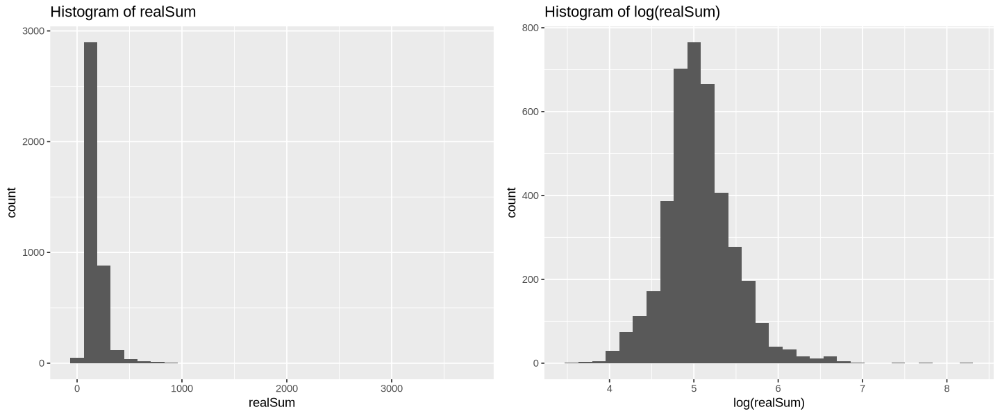

In [6]:
p1 <- ggplot(budapest_combined, aes(x = realSum)) +
  geom_histogram(bins = 30) +
  ggtitle("Histogram of realSum") +
  xlab("realSum")

p2 <- ggplot(budapest_combined, aes(x = log(realSum))) +
  geom_histogram(bins = 30) +
  ggtitle("Histogram of log(realSum)") +
  xlab("log(realSum)")

options(repr.plot.width = 12, repr.plot.height = 5)
cowplot::plot_grid(p1, p2, ncol = 2)

By applying the log-transformation, the highly skewed distribution of `realSum` becomes much more balanced. This stabilized scale is easier for predictive models to learn, so we use `log(realSum)` as the target variable to improve prediction accuracy.

#### Visualization 1

`geom_smooth()` using formula = 'y ~ x'


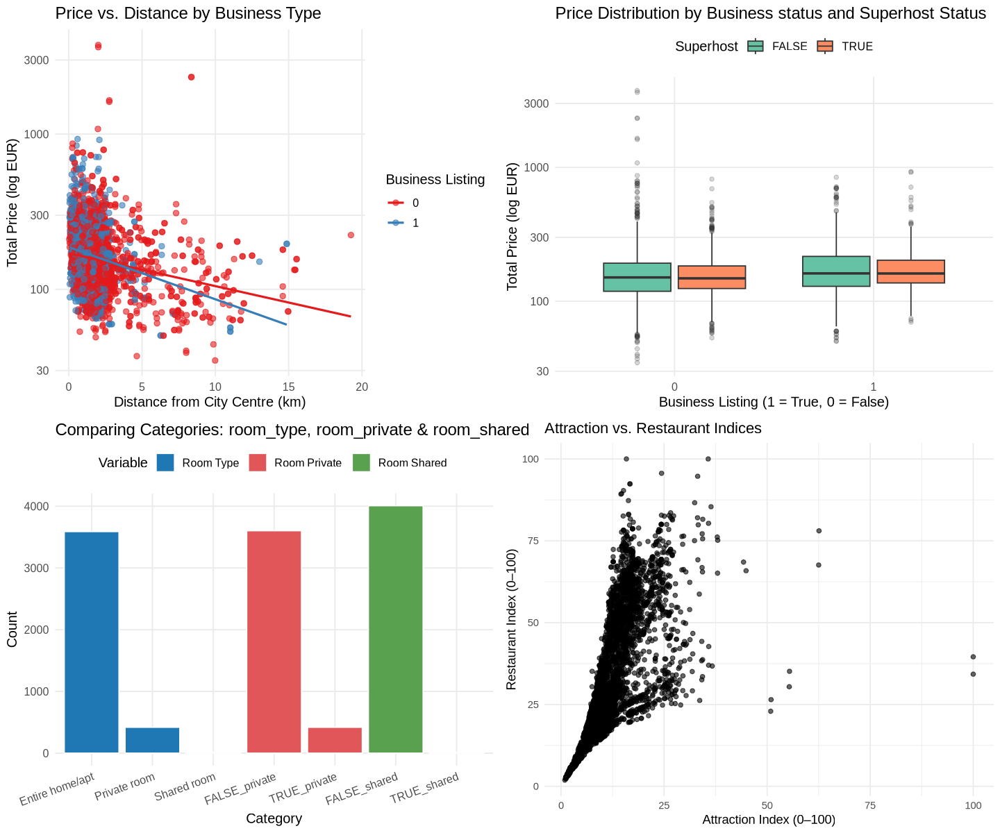

In [7]:
## p1. scatterplot1 realSum vs dist split by biz
p1 <- ggplot(budapest_combined,
       aes(x = dist, y = realSum, color = as.factor(biz))) +
  geom_point(alpha = 0.6, size = 2) +
  geom_smooth(method = "lm", se = FALSE, linewidth = 0.9) +
  scale_color_brewer(palette = "Set1") +
  scale_y_log10() +  # log scale to handle price skew
  labs(
    title = "Price vs. Distance by Business Type",
    x = "Distance from City Centre (km)",
    y = "Total Price (log EUR)",
    color = "Business Listing"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    strip.background = element_rect(fill = "#f5f5f5", color = NA),
    panel.grid.minor = element_blank()
  )
## p2. boxplot realSum vs biz colored by host_is_superhost
p2 <- ggplot(budapest_combined,
       aes(x = factor(biz),
           y = realSum,
           fill = as.factor(host_is_superhost))) +
  geom_boxplot(outlier.alpha = 0.2) +
  scale_y_log10() +  # log scale to handle price skew
  scale_fill_brewer(palette = "Set2") +
  labs(
    title = "Price Distribution by Business status and Superhost Status",
    x = "Business Listing (1 = True, 0 = False)",
    y = "Total Price (log EUR)",
    fill = "Superhost"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.minor = element_blank(),
    legend.position = "top"
  )

## p3. Histogram comparing levels of room_type and private and shared room 
recode_bool <- function(x, true_label, false_label) {
  y <- tolower(as.character(x))
  out <- dplyr::case_when(
    y %in% c("true","t","1")  ~ true_label,
    y %in% c("false","f","0") ~ false_label,
    is.na(x)                  ~ NA_character_,
    TRUE                      ~ y
  )
  factor(out, levels = c(false_label, true_label))
}

airbnb_long_prep <- budapest_combined %>%
  mutate(
    room_type_lbl    = as.factor(room_type),
    room_private_lbl = recode_bool(room_private, "TRUE_private",  "FALSE_private"),
    room_shared_lbl  = recode_bool(room_shared,  "TRUE_shared",   "FALSE_shared")
  ) %>%
  select(room_type_lbl, room_private_lbl, room_shared_lbl)

lvl_type    <- levels(airbnb_long_prep$room_type_lbl)
lvl_private <- levels(airbnb_long_prep$room_private_lbl)   # FALSE_private, TRUE_private
lvl_shared  <- levels(airbnb_long_prep$room_shared_lbl)    # FALSE_shared, TRUE_shared
desired_levels <- c(lvl_type, lvl_private, lvl_shared)

room_all_levels <- airbnb_long_prep %>%
  # only pivot the three room-related columns
  select(room_type_lbl, room_private_lbl, room_shared_lbl) %>%
  pivot_longer(
    cols      = everything(),
    names_to  = "source_var",
    values_to = "category"
  ) %>%
  mutate(
    source_var = factor(
      source_var,
      levels = c("room_type_lbl","room_private_lbl","room_shared_lbl"),
      labels = c("Room Type","Room Private","Room Shared")
    ),
    category = factor(category, levels = desired_levels)
  )

p3 <- ggplot(room_all_levels, aes(x = category, fill = source_var)) +
  geom_bar(color = "white") +
  scale_x_discrete(limits = desired_levels) +
  scale_fill_manual(
    name = "Variable",
    values = c(
      "Room Type"    = "#1f77b4",
      "Room Private" = "#e15759",
      "Room Shared"  = "#59a14f"
    )
  ) +
  labs(
    title = "Comparing Categories: room_type, room_private & room_shared",
    x = "Category",
    y = "Count"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    legend.position = "top",
    panel.grid.minor = element_blank(),
    axis.text.x = element_text(angle = 20, hjust = 1)
  )

## p4. Scatterplot between attr_index_norm and rest_index_norm
p4 <- ggplot(budapest_combined, aes(x = attr_index_norm, y = rest_index_norm)) +
  geom_point(alpha = 0.6) +
  labs(
    title = "Attraction vs. Restaurant Indices",
    x = "Attraction Index (0–100)",
    y = "Restaurant Index (0–100)"
  ) +
  theme_minimal()

corr_matrix_budapest <- 
   budapest_combined %>%
   select(- room_type, 
          - room_shared, 
          - room_private, 
          - host_is_superhost, 
          - multi, 
          - biz,
          - is_weekend) %>% 
   cor() %>%
   as_tibble(rownames = 'var1') %>%
   pivot_longer(-var1, names_to = "var2", values_to = "corr")

options(repr.plot.width = 12, repr.plot.height = 10)
cowplot::plot_grid(p1, p2, p3, p4, ncol = 2)

1. First, we begin by exploring **how subsets of predictors relate to the target variable `realSum`** to identify patterns that may improve predictive performance. 
- Because the price–distance pattern may vary by business use, we create a scatterplot of `dist` against log-transformed `realSum`, split by `biz`.  
     - As shown in **plot (a)**, prices decrease with greater distance from the city centre for both business and non-business listings, with a steeper decline for business listings. This pattern indicates that both predictors, as well as their interaction, may contribute useful predictive signal and should be included in the model.
- We also examine whether business use interacts with host reputation in shaping price patterns. Since both `biz` and `superhost` are categorical, we compare log-`realSum` across business categories and superhost status using boxplots.  
  - From **plot (b)**, non-business listings hosted by superhosts tend to have slightly higher prices, whereas business listings show similar pricing regardless of superhost status. Although subtle, this pattern may still carry predictive value and therefore the interaction may be relevant.

2. Thirdly, we explore how **predictors relate to each other**, since strong dependencies between predictors can affect model stability and predictive performance, especially in linear and regularized models.  
- Within `room_type`, the levels “Private room” and “Shared room” appear closely aligned with the indicator variables `room_private` and `room_shared`. Since all three are categorical, we use a 3-layered bar plot to assess whether the indicators duplicate the information already encoded in `room_type`.  
  - As shown in **plot (c)**, each `room_type` level matches perfectly with the corresponding indicator variable, indicating that `room_private` and `room_shared` are simply redundant encodings. To avoid unnecessary duplication and reduce noise, these indicator variables should be dropped before model fitting.
- For continuous variables, we suspect multicollinearity between `attr_index_norm` and `rest_index_norm`, since their underlying concepts are closely related. We use a scatterplot to assess this relationship.  
   - As shown in **plot (d)**, there is a strong linear association between these variables, suggesting substantial overlap. Because strongly correlated predictors may reduce the efficiency of linear predictions or weaken regularization paths, we will address this later in the modeling stage.
- To obtain a broader view of dependencies among continuous variables, we use `cor()` and `geom_tile()` to construct a heatmap of correlations.  
   - From **plot (e)**, we observe strong relationships such as 0.68 between `rest_index_norm` and `attr_index_norm` and 0.83 between `metro_dist` and `dist`. These patterns confirm notable predictor dependencies that must be considered to ensure stable and accurate predictions in our final models.


#### Visualization 2

ℹ © Stadia Maps © Stamen Design © OpenMapTiles © OpenStreetMap contributors.

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_path()`).”


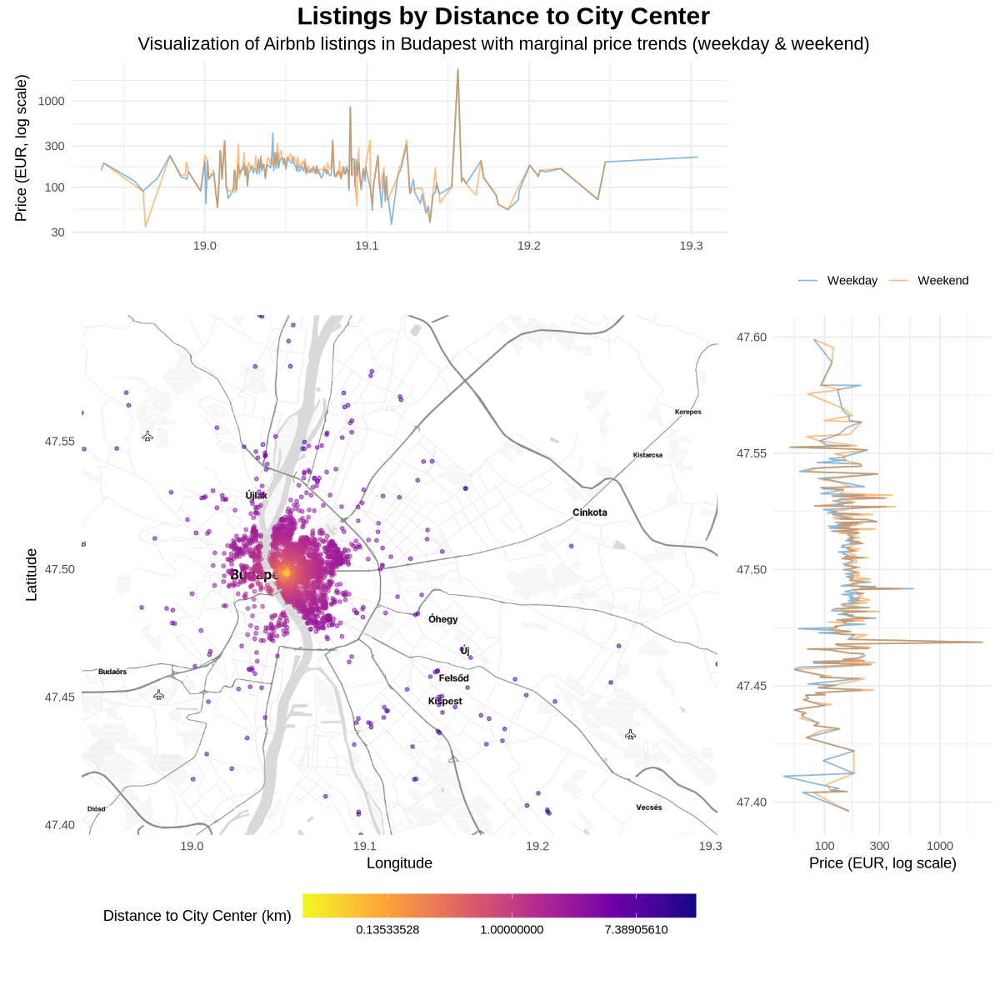

In [8]:
# remove duplicates along lat and lon, for plot cleaniness
budapest_unique <- budapest_combined %>%
  distinct(lat, lng, .keep_all = TRUE)

# correct environment variable name
STADIA_MAP_KEY <- Sys.getenv("STADIA_KEY")

# initialize stadia map with key
register_stadiamaps(key = STADIA_MAP_KEY)

bbox <- c(
  left   = min(budapest_weekday$lng, na.rm = TRUE),
  bottom = min(budapest_weekday$lat, na.rm = TRUE),
  right  = max(budapest_weekday$lng, na.rm = TRUE),
  top    = max(budapest_weekday$lat, na.rm = TRUE)
)

budapest_map <- get_stadiamap(
  bbox = bbox,
  zoom = 12,
  maptype = "stamen_toner_lite",
  filetype = "png" 
)

# TOP PLOT FOR PRICE V LONGTITUDE
top_df <- budapest_combined %>%
  mutate(lng_bin = cut(lng, breaks = 500)) %>%
  group_by(is_weekend, lng_bin) %>%
  summarise(
    lng   = mean(lng, na.rm = TRUE),
    price = mean(realSum, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  arrange(is_weekend, lng)

top <- ggplot(top_df, aes(x = lng, y = price, color = factor(is_weekend))) +
  geom_path(size = 0.5, alpha = 0.5) +
  scale_y_log10() +
  scale_color_manual(
    values = c("FALSE" = "#1f77b4", "TRUE" = "#ff7f0e"),
    labels = c("Weekday", "Weekend"),
    name = NULL
  ) +
  labs(
    x = NULL,
    y = "Price (EUR, log scale)"
  ) +
  theme_minimal(base_size = 11) +
  theme(
    plot.margin = margin(0, 5, 0, 5),
    legend.position = "none"
  )

# RIGHT PLOT FOR PRICE V LATITUDE
right_df <- budapest_combined %>%
  mutate(lat_bin = cut(lat, breaks = 500)) %>%
  group_by(is_weekend, lat_bin) %>%
  summarise(lat = mean(lat),
            price = mean(realSum, na.rm = TRUE),
            .groups = "drop"
  ) %>%
  arrange(is_weekend, lat)

right <- ggplot() +
  geom_path(
    data = right_df,
    aes(x = price, y = lat, color = factor(is_weekend)),
    size = 0.5,
    alpha = 0.5,
  ) +
  scale_x_log10() +
  scale_color_manual(
    values = c("FALSE" = "#1f77b4", "TRUE" = "#ff7f0e"),
    labels = c("Weekday", "Weekend"),
    name = NULL
  ) +
  labs(
    x = "Price (EUR, log scale)",
    y = NULL,
  ) +
  theme_minimal() +
  theme(
    plot.margin = margin(5, 0, 35, 0),
    legend.position = "top"
  )

# SCALING THE PLOT TO ALIGN AXIS
top <- top +
  scale_x_continuous(limits = c(bbox["left"], bbox["right"]))

right <- right +
  scale_y_continuous(limits = c(bbox["bottom"], bbox["top"]))

# MAPS PLOT
p1 <- ggmap(budapest_map) +
      geom_point(
        data = budapest_unique,
        aes(x = lng, y = lat, color = dist),
        alpha = 0.5, size = 1
      ) +
      scale_color_viridis_c(option = "plasma", direction = -1, trans = "log") +
      labs(
        x = "Longitude", y = "Latitude",
        color = "Distance to City Center (km)"
      ) +
      theme_minimal() +
      theme(
        legend.position = "bottom",
        legend.box = "horizontal",
        legend.key.width = unit(2, "cm"),
        legend.margin = margin(t = 5, b = 5)
      )

options(repr.plot.width = 10, repr.plot.height = 10)

layout <- "
BBB#
AAAC
AAAC
AAAC
"

design <- c(
  area(1, 1, 2),
  area(1, 2, 1, 3),
  area(2, 3, 3),
  area(3, 1, 3, 2),
  area(2, 2)
)

p1 <- p1 + top + right + plot_layout(design = layout) + plot_annotation(
    title = "Listings by Distance to City Center",
    subtitle = "Visualization of Airbnb listings in Budapest with marginal price trends (weekday & weekend)",
    theme = theme(
      plot.title = element_text(size = 18, face = "bold", hjust = 0.5),
      plot.subtitle = element_text(size = 13, hjust = 0.5),
    )
  )

cowplot::plot_grid(p1, ncol = 1)

**Relevance:** This visualization provides an intuitive overview of how price of Airbnb is associated to the distance from city center. By presenting this spatially, it allows for easy visual cross-referencing and helps validate the relevance of these features before modeling. While not directly used for model fitting, this serves as a valuable exploratory step to confirm data coverage and contextual patterns (e.g., the absence of listings over rivers).

**Results Obtained:** Listings are densely concentrated near the city center. Enforcing the relationship between centrality and amenitity access. We also see rapid variation in data toward the center, with a general price increase toward the center. 

**Insights:** Proximity to center appears to is not strongly associated with pricing, contrary to intuition where central locations affect pricing. However, this is likely explained by the unaccounted factors such as size, room type, privacy, etc. This can be seen by the high variantion in the pricing line close to the center and much more spaced out in the sparse regions.

### Methods: Plan

To address our research question, we will fit a multiple linear regression model because it allows us to evaluate how listing characteristics contribute to **predicting** Airbnb prices while accounting for other factors. The proposed plan is as follows:

1) **Further pre-selection of variables** based on results from Visualization 1, and drop `room_shared` and `room_private` since they are simply two levels of the variable `room_type` and do not add additional predictive information.

2) **Perform a log transformation on `realSum`**, as explored in the EDA. This makes the distribution more symmetric and helps linearize relationships between price and predictors, which better supports a linear model for prediction. This is also the only transformation we plan to apply to avoid over-complicating the model and to maintain clarity in interpreting predicted values.

3) **Split the dataset into training and testing sets.** Fitting and evaluating a model on the same data tends to overestimate predictive performance because the model can partially "memorize" noise in the training set. Using a separate test set provides a more realistic estimate of how well the model generalizes to new listings—especially important when the goal is prediction rather than explanation.

4) **Perform L1 regularization (LASSO)** to select and train the model using cross-validation. LASSO adds a penalty on the absolute size of coefficients, shrinking some coefficients exactly to zero and effectively performing variable selection. This helps prevent overfitting, simplifies the model, and highlights the most predictive covariates for price. Cross-validation is used to choose the penalty strength (λ) that balances bias and variance for optimal predictive performance on unseen data.

5) **Results: Evaluate the trained model on the test set** to measure out-of-sample predictive accuracy and assess how well the model performs on new Airbnb listings.


### Code and Results

#### Step1: Further Preselection

In [9]:
str(budapest_combined)

'data.frame':	4022 obs. of  18 variables:
 $ realSum                   : num  239 301 162 118 134 ...
 $ room_type                 : chr  "Entire home/apt" "Entire home/apt" "Entire home/apt" "Entire home/apt" ...
 $ room_shared               : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ room_private              : logi  FALSE FALSE FALSE FALSE FALSE FALSE ...
 $ person_capacity           : num  6 6 4 2 4 4 4 4 6 4 ...
 $ host_is_superhost         : logi  TRUE FALSE TRUE FALSE TRUE FALSE ...
 $ multi                     : num  0 0 0 0 1 1 0 0 0 0 ...
 $ biz                       : num  1 1 0 0 0 0 0 1 1 0 ...
 $ cleanliness_rating        : num  10 9 10 9 10 9 6 9 10 10 ...
 $ guest_satisfaction_overall: num  99 98 98 92 99 91 80 92 88 96 ...
 $ bedrooms                  : num  1 2 1 1 2 2 2 1 2 1 ...
 $ dist                      : num  0.359 0.929 2.451 1.559 1.114 ...
 $ metro_dist                : num  0.353 0.2 0.279 0.478 0.27 ...
 $ attr_index_norm           : num  24.12 100 

In [10]:
budapest_combined <- budapest_combined %>%
     select( -room_shared, -room_private)

#### Step 2: Transformation

In [11]:
budapest_combined <- budapest_combined %>%
  mutate(log_realSum = log(realSum))

#### Step 3: Train-Test Split (80/20)

In [12]:
set.seed(123)  # for reproducibility

n <- nrow(budapest_combined)
train_size <- floor(0.8 * n)

train_idx <- sample(seq_len(n), size = train_size)

budapest_train <- budapest_combined[train_idx, ]
budapest_test  <- budapest_combined[-train_idx, ]

#### Step 4: Regularization and Model Selection

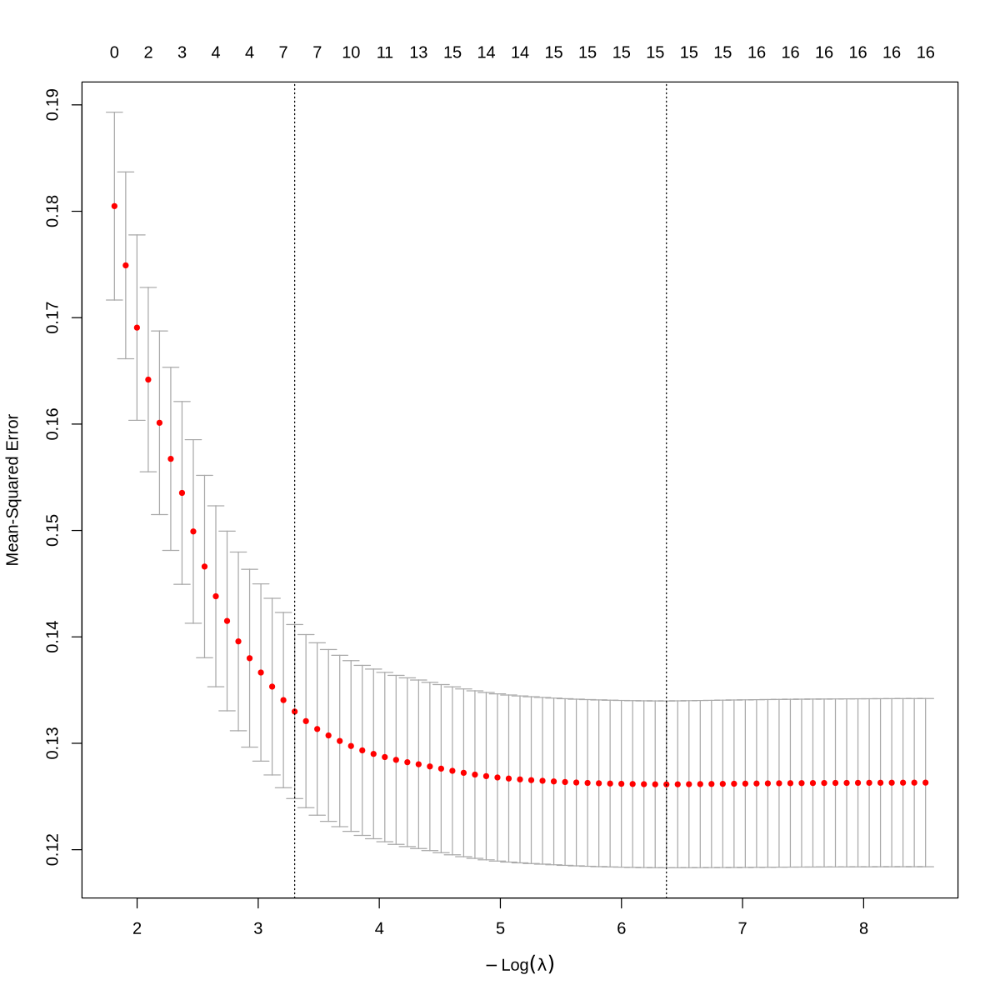

In [13]:
# Build design matrix for glmnet
y_train <- budapest_train$log_realSum
X_train <- model.matrix(
  log_realSum ~ . - realSum,
  data = budapest_train
)[, -1]

cv_lasso <- cv.glmnet(
  x = X_train,
  y = y_train,
  alpha = 1,      # LASSO (L1)
  nfolds = 10,    # 10-fold cross-validation
  standardize = TRUE  # default, but explicit
)

par(bg = "white")
plot(cv_lasso)


We see that `lambda.min` is not really useful as it didn't help us shrink down the coefficient nor did select any variables. Thus we are going to use `lambda.1se` as it cuts down our number of covariates while maintaining an acceptable MSE.

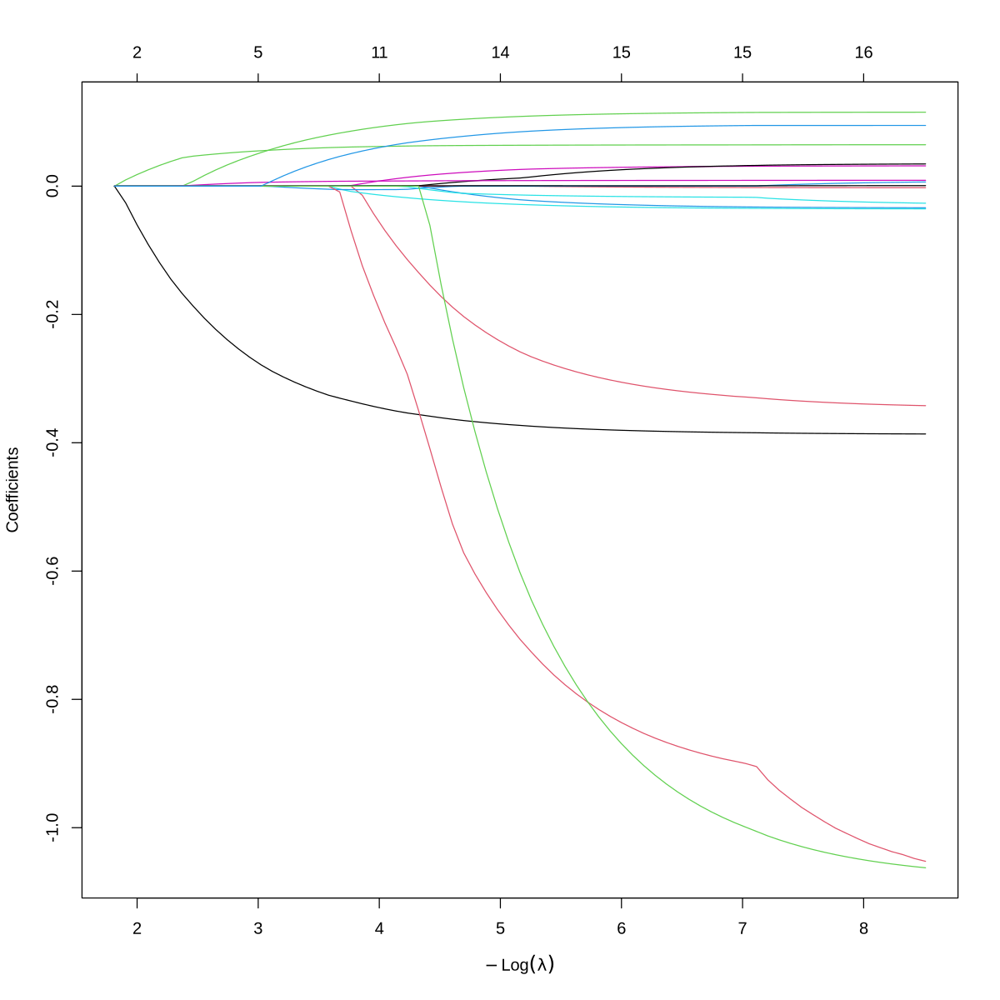

In [14]:
par(bg = "white")
plot(cv_lasso$glmnet.fit, "lambda")
abline(v = log(cv_lasso$lambda.1se), col = "red", lty = 2)

In [15]:
coef_min  <- coef(cv_lasso, s = "lambda.1se")
coef_min

17 x 1 sparse Matrix of class "dgCMatrix"
                             lambda.1se
(Intercept)                 4.720613114
room_typePrivate room      -0.305618898
room_typeShared room        .          
person_capacity             0.057948897
host_is_superhostTRUE       .          
multi                       .          
biz                         .          
cleanliness_rating          .          
guest_satisfaction_overall  .          
bedrooms                    0.067683981
dist                       -0.002496579
metro_dist                  .          
attr_index_norm             0.006757340
rest_index_norm             0.000151294
lng                         .          
lat                         .          
is_weekendTRUE              0.023355077

We applied L1-regularized regression (LASSO) with 10-fold cross-validation to tune the regularization strength. We selected λ_1se, the maximum value of λ such that the corresponding MSE is within 1se of the minimum, this way we can perform effective model selection while not compromising too much on model performance.

#### Step5: Evaluation and Result

Since we are doing prediction instead of inference, we do not need to refit an unpenalized least squares model on the selected variables; instead, we can directly use the cross-validated LASSO model.

In [16]:
# Response on test set
y_test_log <- budapest_test$log_realSum

# Predictors on test set
X_test <- model.matrix(
  log_realSum ~ . - realSum,
  data = budapest_test
)[, -1]

# Predictions using λ_min
pred_log <- as.numeric(
  predict(cv_lasso, s = "lambda.min", newx = X_test)
)


#### **Visualization 1**: Model Performance Metrics on Log and Original Price Scales

To evaluate how well the LASSO model predicts Airbnb prices, we compute three standard predictive metrics—RMSE, MAE, and R²—on both the log-transformed scale (the modeling scale) and the original price scale (the interpretation scale). The results are summarized in the follwing table.

In [17]:
# Evaluation metrics on log scale   
rmse_log <- sqrt(mean((y_test_log - pred_log)^2))
mae_log  <- mean(abs(y_test_log - pred_log))

ss_res <- sum((y_test_log - pred_log)^2)
ss_tot <- sum((y_test_log - mean(y_test_log))^2)
r2_log <- 1 - ss_res / ss_tot

# Evaluation metrics on original price scale
pred_price <- exp(pred_log)
y_test_price <- budapest_test$realSum

rmse_price <- sqrt(mean((y_test_price - pred_price)^2))
mae_price  <- mean(abs(y_test_price - pred_price))

ss_res_price <- sum((y_test_price - pred_price)^2)
ss_tot_price <- sum((y_test_price - mean(y_test_price))^2)
r2_price <- 1 - ss_res_price / ss_tot_price


metrics_table <- data.frame(
  Metric        = c("RMSE",          "MAE",          "R squared"),
  log_realSum   = c(rmse_log,        mae_log,        r2_log),
  realSum       = c(rmse_price,      mae_price,      r2_price)
)
metrics_table

Metric,log_realSum,realSum
<chr>,<dbl>,<dbl>
RMSE,0.3274405,88.8098099
MAE,0.2458939,44.9504005
R squared,0.3500129,0.1555383


**Table 1: Predictive Performance Metrics on Log Scale and Original Price Scale**

|Metric    | log_realSum | realSum |
|:---------|:-----------:|:-------:|
|RMSE      |   0.3275    | 88.8052 |
|MAE       |   0.2459    | 44.9536 |
|R squared |   0.3500    | 0.1556  |

**Interpretation**

On the **log scale**, the model achieves:
- **RMSE = 0.327**
- **MAE = 0.246**
- **R² = 0.35**
These values indicate that the model is able to *capture meaningful structure in the data and make reasonably accurate predictions of log-price for unseen listings*. Because the log scale stabilizes variance and reduces the influence of extreme values, it is the most appropriate scale for assessing predictive performance of this model.

When predictions are converted back to the **original Airbnb price scale**, we obtain:
- **RMSE ≈ €88.81**
- **MAE ≈ €44.95**
- **R² ≈ 0.16**
Predictive performance on the original scale is naturally more challenging due to the wide range of prices and the presence of high-value listings, which inflate absolute errors. Even so, an MAE of about €45 suggests that the model provides **useful price estimates for most listings**, given the inherent variability of Airbnb pricing.

Taken together, these results show that the **LASSO model generalizes well, with stronger predictive accuracy on the log scale**—where relationships are more linear—and solid performance on the original price scale for practical interpretation of predictions.

#### **Visualization 2(Predictive Performance)**: Residual Plot on Test Set

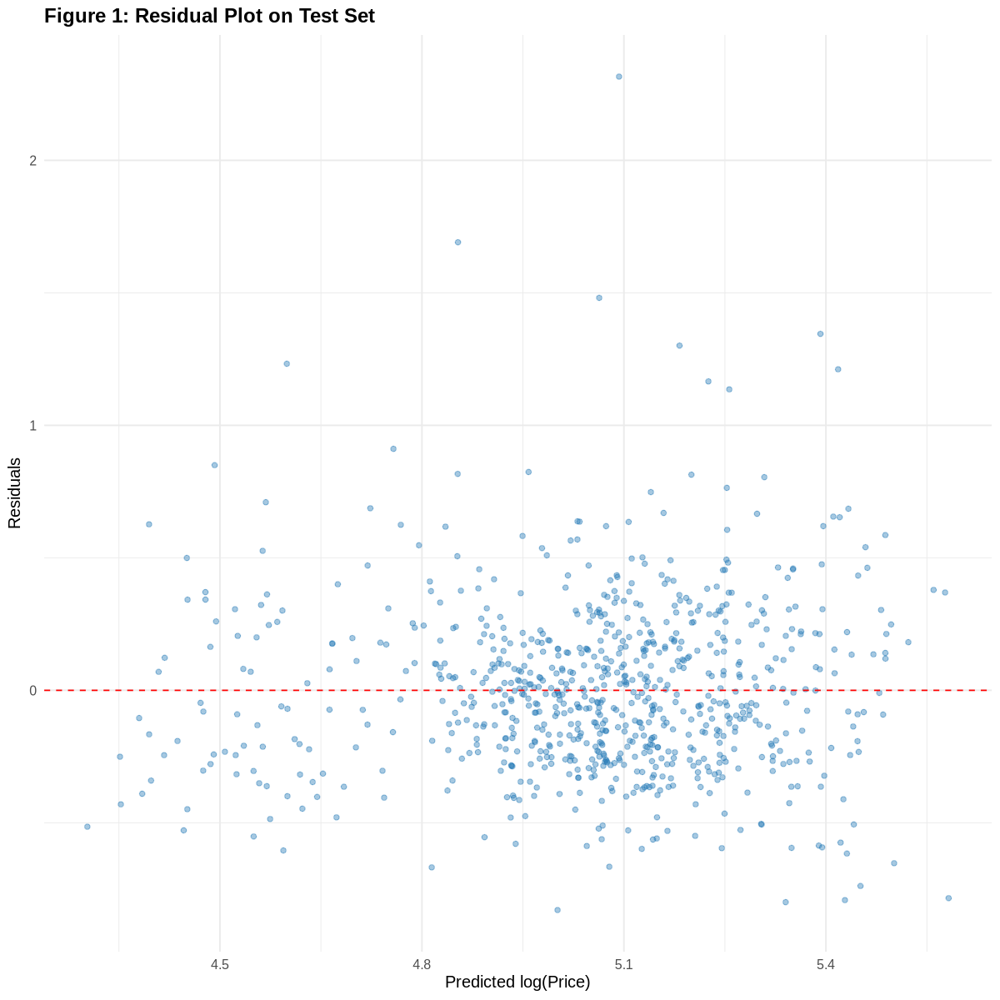

In [18]:
# Compute residuals on test set
residuals_log <- y_test_log - pred_log

# Residual plot
ggplot(data.frame(pred_log, residuals_log), aes(x = pred_log, y = residuals_log)) +
  geom_point(alpha = 0.4, color = "#1f77b4") +
  geom_hline(yintercept = 0, linetype = "dashed", color = "red") +
  labs(
    title = "Figure 1: Residual Plot on Test Set",
    x = "Predicted log(Price)",
    y = "Residuals"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold")
  )

**Interpretation**

The residual plot shows that most residuals are tightly clustered around zero, indicating that the model is generally producing accurate predictions of log-price on unseen data. The absence of a strong upward or downward trend suggests that the model does not systematically over- or under-predict across the range of predicted values.
The spread of residuals increases slightly for higher predicted log-prices, which is common in price-prediction tasks because more expensive listings naturally exhibit greater variability. Importantly, the residuals remain roughly symmetric around zero, and no clear structure or pattern is present—both of which support the conclusion that the model generalizes reasonably well.
**Overall, the residual behavior is consistent with a predictive model that captures the key relationships driving Airbnb prices while maintaining stable performance across different price levels.**

#### **Visualization 3**: Actual vs Predicted Prices on Test Set

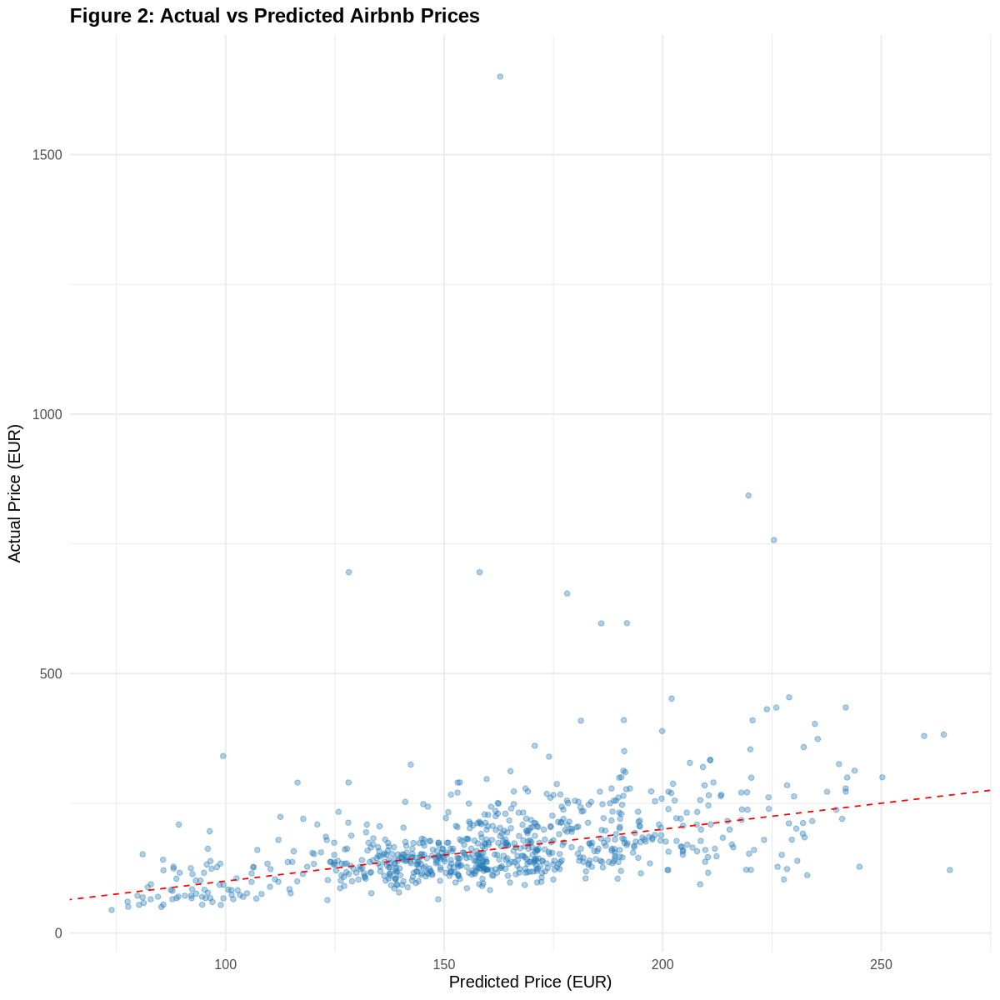

In [19]:
# Convert predictions back to original scale
pred_price <- exp(pred_log)
y_test_price <- budapest_test$realSum

# Actual vs Predicted plot
ggplot(data.frame(pred_price, y_test_price),
       aes(x = pred_price, y = y_test_price)) +
  geom_point(alpha = 0.35, color = "#1f77b4") +
  geom_abline(slope = 1, intercept = 0, color = "red", linetype = "dashed") +
  labs(
    title = "Figure 2: Actual vs Predicted Airbnb Prices",
    x = "Predicted Price (EUR)",
    y = "Actual Price (EUR)"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold")
  )

**Interpretation**

The points cluster around the regression line, indicating that the model **predicts Airbnb prices reasonably well for most listings**. The spread widens for higher-priced properties, which is expected because the model was trained on the log scale—meaning small errors in log space become larger absolute errors once converted back to euros.

Even with this natural increase in variability at the upper end, the overall alignment between actual and predicted prices shows that the model captures key pricing patterns and generalizes effectively to new listings. This visualization **reinforces the performance metrics in Table 1 and highlights the model’s practical predictive accuracy**.

## Discussion
### Summary of Findings
Our LASSO model selected nine predictors that contributed to improving Airbnb price prediction in Budapest, achieving an R-squared of **0.35** on the log scale and a mean absolute error of approximately 45 euros on the original price scale. Among the selected features, room type, person capacity, number of bedrooms, weekend status, and location-related indices (attraction index, restaurant index, longitude) were retained as useful for prediction. In contrast, several variables—including shared room indicators, superhost status, business listing status, cleanliness rating, guest satisfaction, and latitude—were shrunk to zero, indicating that they did not enhance the model’s predictive accuracy once other structural and location features were included.

These results suggest that **room characteristics and spatial featur es carry most of the predictive signal** in determining Airbnb prices for this dataset. Notably, reputation metrics such as superhost status and overall satisfaction ratings did not improve prediction, meaning that the model was able to achieve its best performance without relying on these variables. This directly addresses our research question: within this modeling framework, host reputation did not contribute additional predictive value beyond structural and location attributes.

### Model Improvements and Future Research
Predictive performance could be improved through additional feature engineering, such as including interaction terms between room characteristics and location features, or refining spatial variables (e.g., distance to specific landmarks rather than general city-center distance). Nonlinear models or tree-based methods may capture relationships that LASSO cannot fully represent. Future research could also explore seasonality, high-demand periods, or cross-city comparisons to understand how predictive drivers of price vary across time and location.

## References

Gibbs, C., Guttentag, D., Gretzel, U., Morton, J., & Goodwill, A. (2018). Pricing in the sharing economy: A hedonic pricing model applied to Airbnb listings. *Journal of Travel & Tourism Marketing*, *35*(2), 46-56. https://doi.org/10.1080/10548408.2017.1308293

Gyódi, K., & Nawaro, L. (2021). Determinants of Airbnb prices in European cities: A spatial econometrics approach. *Tourism Management*, *86*, 104319. https://doi.org/10.1016/j.tourman.2021.104319

Zhang, Z., Chen, R. J. C., Han, L. D., & Yang, L. (2017). Key factors affecting the price of Airbnb listings: A geographically weighted approach. *Sustainability*, *9*(9), 1635. https://doi.org/10.3390/su9091635